In [4]:
!pip install -q roboflow

In [5]:
from roboflow import Roboflow

rf = Roboflow(api_key="T1kWUvfSQp8u4BquZIYm")

project = rf.workspace("dog-skin-disease-dermatosis").project(
    "dog-skin-disease-dataset"
)

dataset = project.version(2).download("folder")

print("Dataset location:", dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Dog-Skin-Disease-Dataset-2 in folder:: 100%|██████████| 4415/4415 [00:01<00:00, 2675.56it/s]

Dataset location: /content/Dog-Skin-Disease-Dataset-2


In [6]:
import os, torch
from collections import Counter

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

DATA_DIR = dataset.location
print("\nDataset root:", DATA_DIR)
print("Top-level contents:", os.listdir(DATA_DIR))

for split in ["train", "valid", "test"]:
    split_path = os.path.join(DATA_DIR, split)
    if not os.path.isdir(split_path):
        print(f"\n[{split}] folder NOT found")
        continue
    classes = sorted(os.listdir(split_path))
    counts = {c: len(os.listdir(os.path.join(split_path, c))) for c in classes
              if os.path.isdir(os.path.join(split_path, c))}
    print(f"\n[{split}] {len(counts)} classes, {sum(counts.values())} images")
    for c, n in counts.items():
        print(f"   {c:40s} {n}")

PyTorch: 2.14.1+cu130
GPU available: True
GPU: Tesla T4

Dataset root: /content/Dog-Skin-Disease-Dataset-2
Top-level contents: ['README.dataset.txt', 'README.roboflow.txt', 'test', 'valid', 'train']

[train] 4 classes, 3851 images
   bacterial dermatosis                     954
   fungal infection                         1053
   healthy                                  1037
   hypersensitivity dermatitis              807

[valid] 4 classes, 367 images
   bacterial dermatosis                     98
   fungal infection                         101
   healthy                                  98
   hypersensitivity dermatitis              70

[test] 4 classes, 180 images
   bacterial dermatosis                     45
   fungal infection                         47
   healthy                                  51
   hypersensitivity dermatitis              37


Data loaders and augmentation

Device: cuda
Classes: {'bacterial dermatosis': 0, 'fungal infection': 1, 'healthy': 2, 'hypersensitivity dermatitis': 3}
Train 3851 | Val 367 | Test 180
Class weights: [1.009 0.914 0.928 1.193]


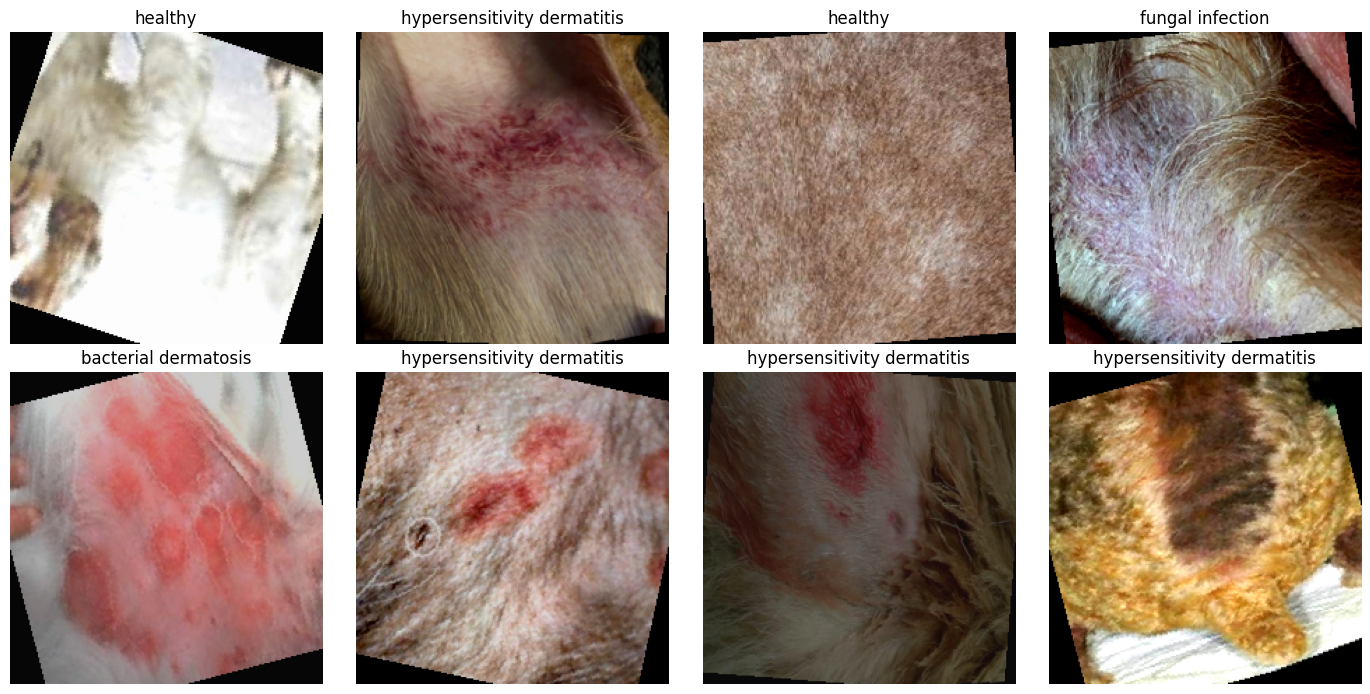

In [7]:
import torch, numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

IMG_SIZE = 224
BATCH_SIZE = 32
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(f"{DATA_DIR}/train", transform=train_tfms)
val_ds   = datasets.ImageFolder(f"{DATA_DIR}/valid", transform=eval_tfms)
test_ds  = datasets.ImageFolder(f"{DATA_DIR}/test",  transform=eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_names = train_ds.classes
NUM_CLASSES = len(class_names)
print("Classes:", train_ds.class_to_idx)
print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}")

# Class weights (handles the mild imbalance)
counts = np.bincount(train_ds.targets)
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float).to(device)
print("Class weights:", class_weights.cpu().numpy().round(3))

# Preview one augmented batch
imgs, labels = next(iter(train_loader))
mean, std = torch.tensor(MEAN).view(3,1,1), torch.tensor(STD).view(3,1,1)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, img, lab in zip(axes.flat, imgs[:8], labels[:8]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(class_names[lab]); ax.axis("off")
plt.tight_layout(); plt.show()

Build EfficientNet-B0 and train stage 1 (head only)

In [8]:
import torch.nn as nn, time
from torchvision import models
from torch.amp import autocast, GradScaler

assert device.type == "cuda", "Switch runtime to GPU first (Runtime > Change runtime type > T4 GPU)"

# --- Model ---
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
in_f = model.classifier[1].in_features
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(in_f, NUM_CLASSES))
model = model.to(device)

# Freeze backbone for stage 1
for p in model.features.parameters():
    p.requires_grad = False

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
scaler = GradScaler("cuda")

def run_epoch(loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast("cuda"):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

# --- Stage 1: train classifier head only ---
EPOCHS_1 = 5
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val = 0.0

for epoch in range(1, EPOCHS_1 + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, optimizer)
    vl, va = run_epoch(val_loader)
    for k, v in zip(history, (tl, ta, vl, va)):
        history[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), "best_model.pth")
    print(f"[Stage 1] Epoch {epoch}/{EPOCHS_1} | "
          f"train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s")

print("Best val acc:", round(best_val, 4))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 67.8MB/s]


[Stage 1] Epoch 1/5 | train loss 1.0740 acc 0.6167 | val loss 0.8742 acc 0.7384 | 51s
[Stage 1] Epoch 2/5 | train loss 0.8733 acc 0.7414 | val loss 0.8063 acc 0.7820 | 44s
[Stage 1] Epoch 3/5 | train loss 0.8259 acc 0.7637 | val loss 0.7713 acc 0.7793 | 44s
[Stage 1] Epoch 4/5 | train loss 0.7803 acc 0.7925 | val loss 0.7462 acc 0.8065 | 45s
[Stage 1] Epoch 5/5 | train loss 0.7785 acc 0.7886 | val loss 0.7306 acc 0.8174 | 44s
Best val acc: 0.8174


Stage 2, fine-tune the whole network

[Stage 2] Epoch 1/15 | train loss 0.6655 acc 0.8515 | val loss 0.5987 acc 0.9074 | 52s  <- saved
[Stage 2] Epoch 2/15 | train loss 0.5319 acc 0.9338 | val loss 0.5442 acc 0.9346 | 47s  <- saved
[Stage 2] Epoch 3/15 | train loss 0.4746 acc 0.9670 | val loss 0.5240 acc 0.9455 | 49s  <- saved
[Stage 2] Epoch 4/15 | train loss 0.4510 acc 0.9756 | val loss 0.5072 acc 0.9455 | 47s
[Stage 2] Epoch 5/15 | train loss 0.4344 acc 0.9857 | val loss 0.4873 acc 0.9537 | 49s  <- saved
[Stage 2] Epoch 6/15 | train loss 0.4255 acc 0.9891 | val loss 0.4914 acc 0.9455 | 47s
[Stage 2] Epoch 7/15 | train loss 0.4171 acc 0.9914 | val loss 0.4801 acc 0.9619 | 49s  <- saved
[Stage 2] Epoch 8/15 | train loss 0.4156 acc 0.9927 | val loss 0.4801 acc 0.9591 | 48s
[Stage 2] Epoch 9/15 | train loss 0.4101 acc 0.9912 | val loss 0.4803 acc 0.9564 | 50s
[Stage 2] Epoch 10/15 | train loss 0.4047 acc 0.9958 | val loss 0.4762 acc 0.9537 | 48s
[Stage 2] Epoch 11/15 | train loss 0.4038 acc 0.9940 | val loss 0.4814 acc 0.95

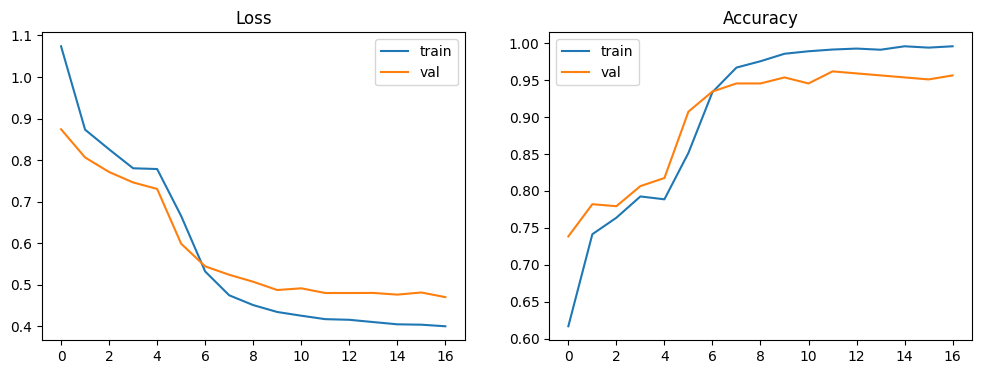

In [9]:
# --- Stage 2: unfreeze everything ---
for p in model.parameters():
    p.requires_grad = True

EPOCHS_2 = 15
PATIENCE = 5

optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(),   "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 5e-4},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_2, eta_min=1e-6)

no_improve = 0
for epoch in range(1, EPOCHS_2 + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, optimizer)
    vl, va = run_epoch(val_loader)
    scheduler.step()
    for k, v in zip(history, (tl, ta, vl, va)):
        history[k].append(v)

    flag = ""
    if va > best_val:
        best_val = va
        no_improve = 0
        torch.save(model.state_dict(), "best_model.pth")
        flag = "  <- saved"
    else:
        no_improve += 1

    print(f"[Stage 2] Epoch {epoch}/{EPOCHS_2} | "
          f"train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s{flag}")

    if no_improve >= PATIENCE:
        print(f"Early stopping: no val improvement for {PATIENCE} epochs.")
        break

print("Best val acc:", round(best_val, 4))

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

Test accuracy: 0.9389

                             precision    recall  f1-score   support

       bacterial dermatosis      0.932     0.911     0.921        45
           fungal infection      0.935     0.915     0.925        47
                    healthy      1.000     1.000     1.000        51
hypersensitivity dermatitis      0.872     0.919     0.895        37

                   accuracy                          0.939       180
                  macro avg      0.935     0.936     0.935       180
               weighted avg      0.940     0.939     0.939       180



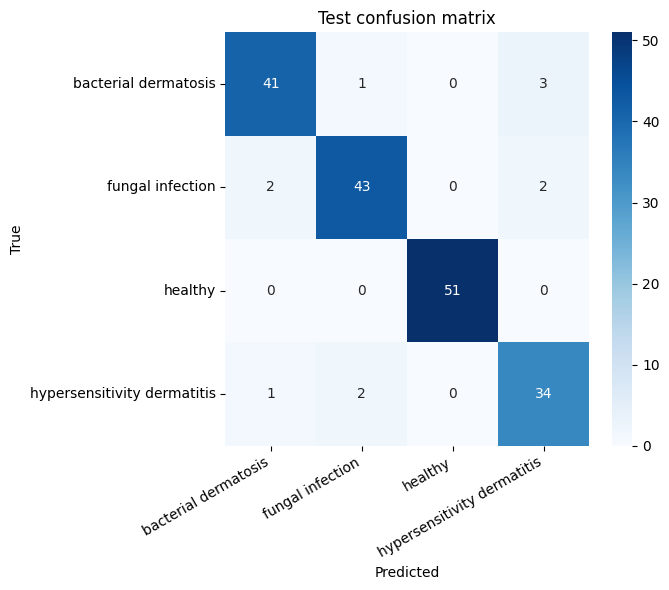

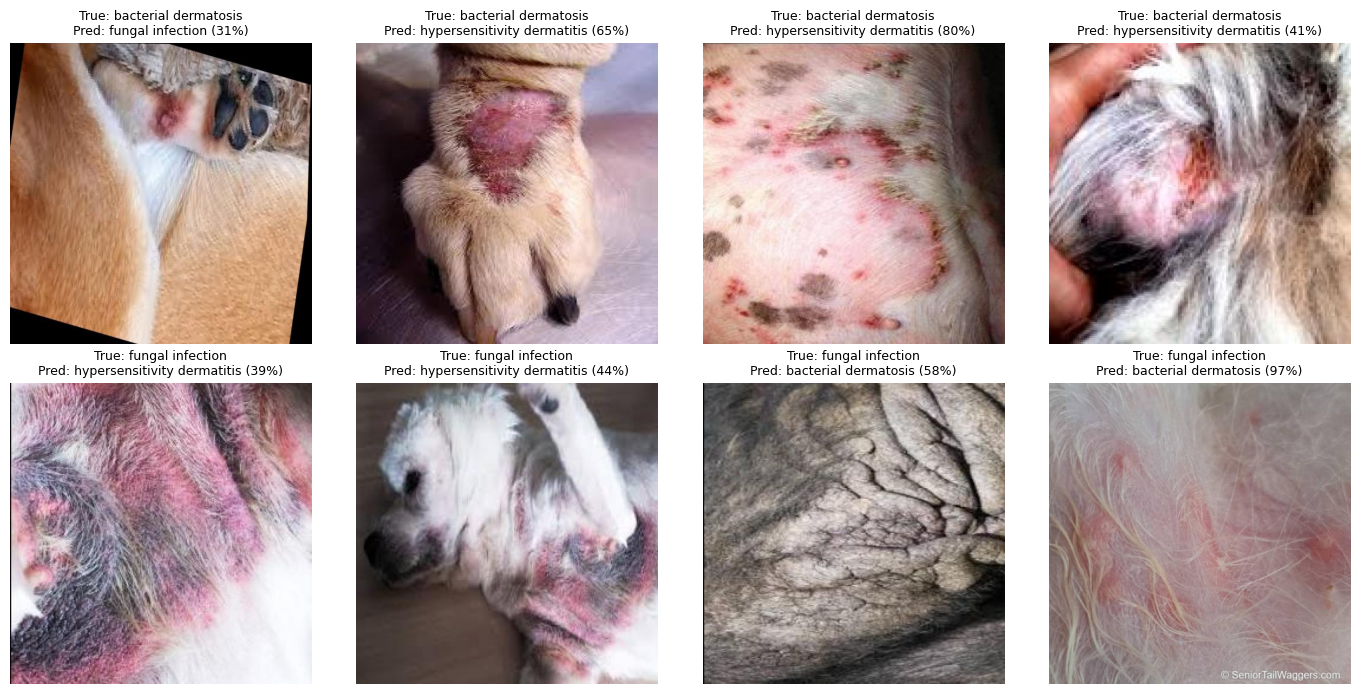

In [10]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Load the best checkpoint (epoch with highest val acc)
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.eval()

all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        with autocast("cuda"):
            out = model(x)
        probs = torch.softmax(out.float(), dim=1)
        all_probs.append(probs.cpu())
        all_preds.extend(probs.argmax(1).cpu().tolist())
        all_labels.extend(y.tolist())

test_acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(f"Test accuracy: {test_acc:.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

# Show some misclassified test images
probs_all = torch.cat(all_probs)
wrong = [i for i, (p, l) in enumerate(zip(all_preds, all_labels)) if p != l][:8]
if wrong:
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, i in zip(axes.flat, wrong):
        img_path, _ = test_ds.samples[i]
        ax.imshow(plt.imread(img_path))
        conf = probs_all[i, all_preds[i]].item()
        ax.set_title(f"True: {class_names[all_labels[i]]}\nPred: {class_names[all_preds[i]]} ({conf:.0%})", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()


In [11]:
import os, hashlib
from collections import defaultdict

def collect(split):
    src = defaultdict(list)   # original-image key -> files
    md5 = defaultdict(list)   # exact byte hash -> files
    for c in class_names:
        folder = f"{DATA_DIR}/{split}/{c}"
        for f in os.listdir(folder):
            key = f.split(".rf.")[0]
            src[key].append((c, f))
            with open(os.path.join(folder, f), "rb") as fh:
                md5[hashlib.md5(fh.read()).hexdigest()].append((c, f))
    return src, md5

tr_src, tr_md5 = collect("train")
va_src, va_md5 = collect("valid")
te_src, te_md5 = collect("test")

print("Sample test filenames:", [v[0][1] for v in list(te_src.values())[:3]])

def overlap(a, b, name):
    shared = set(a) & set(b)
    n_files = sum(len(b[k]) for k in shared)
    print(f"{name}: {len(shared)} shared keys -> {n_files} files affected")
    return shared

print("\n--- Same original image (name before '.rf.') ---")
s_tt = overlap(tr_src, te_src, "train & test ")
s_tv = overlap(tr_src, va_src, "train & valid")
s_vt = overlap(va_src, te_src, "valid & test ")

print("\n--- Byte-identical files ---")
overlap(tr_md5, te_md5, "train & test ")
overlap(tr_md5, va_md5, "train & valid")

print("\n--- Duplicates inside train itself ---")
dups = sum(1 for v in tr_src.values() if len(v) > 1)
print(f"{dups} original images appear more than once in train")

Sample test filenames: ['bacterial_59_jpg.rf.97e06680cba4af875a3531ac09674331.jpg', 'bacterial_399_jpg.rf.95a2645a57427ebc5870579495d9dad5.jpg', 'bacterial_410_jpg.rf.a6c0c0e1b338240d8f0a1000eb325c3b.jpg']

--- Same original image (name before '.rf.') ---
train & test : 3 shared keys -> 3 files affected
train & valid: 8 shared keys -> 8 files affected
valid & test : 1 shared keys -> 1 files affected

--- Byte-identical files ---
train & test : 0 shared keys -> 0 files affected
train & valid: 0 shared keys -> 0 files affected

--- Duplicates inside train itself ---
1264 original images appear more than once in train


In [12]:
# Drop test files whose original image also appears in train or valid
leaky_keys = (set(tr_src) | set(va_src)) & set(te_src)

clean_idx = [i for i, (path, _) in enumerate(test_ds.samples)
             if os.path.basename(path).split(".rf.")[0] not in leaky_keys]
print(f"Clean test images: {len(clean_idx)} of {len(test_ds)} (removed {len(test_ds)-len(clean_idx)})")

preds = np.array(all_preds)[clean_idx]
labels = np.array(all_labels)[clean_idx]

print(f"\nClean test accuracy: {(preds == labels).mean():.4f}\n")
print(classification_report(labels, preds, target_names=class_names, digits=3))

Clean test images: 176 of 180 (removed 4)

Clean test accuracy: 0.9375

                             precision    recall  f1-score   support

       bacterial dermatosis      0.932     0.911     0.921        45
           fungal infection      0.930     0.909     0.920        44
                    healthy      1.000     1.000     1.000        51
hypersensitivity dermatitis      0.868     0.917     0.892        36

                   accuracy                          0.938       176
                  macro avg      0.933     0.934     0.933       176
               weighted avg      0.938     0.938     0.938       176



In [13]:
import json, shutil
from PIL import Image

# 1) Full checkpoint with everything needed to reload later
checkpoint = {
    "model_state": torch.load("best_model.pth", map_location="cpu"),
    "class_names": class_names,
    "img_size": IMG_SIZE,
    "mean": MEAN,
    "std": STD,
    "arch": "efficientnet_b0",
    "clean_test_acc": 0.9375,
}
torch.save(checkpoint, "dog_skin_efficientnet_b0.pth")
json.dump(class_names, open("class_names.json", "w"))

# 2) Inference function: photo in -> prediction + confidence per class
def predict(image_path, threshold=0.60):
    model.eval()
    img = Image.open(image_path).convert("RGB")
    x = eval_tfms(img).unsqueeze(0).to(device)
    with torch.no_grad(), autocast("cuda"):
        probs = torch.softmax(model(x).float(), dim=1)[0].cpu().numpy()
    top = int(probs.argmax())
    result = {
        "prediction": class_names[top],
        "confidence": float(probs[top]),
        "uncertain": bool(probs[top] < threshold),
        "all_probs": {c: round(float(p), 3) for c, p in zip(class_names, probs)},
    }
    return result

# 3) Quick test on a few test images
import random
for path, label in random.sample(test_ds.samples, 3):
    r = predict(path)
    print(f"True: {class_names[label]:28s} -> {r['prediction']} ({r['confidence']:.0%})"
          f"{'  [UNCERTAIN]' if r['uncertain'] else ''}")

# 4) Download to your computer (or copy to Drive instead)
from google.colab import files
files.download("dog_skin_efficientnet_b0.pth")
files.download("class_names.json")

True: hypersensitivity dermatitis  -> hypersensitivity dermatitis (96%)
True: healthy                      -> healthy (89%)
True: healthy                      -> healthy (92%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>